# Phase 2 — Data Processing & EDA

This notebook executes the rebuilt workflow from the existing official raw files. Only development date_id **0–8867** (8,868 rows) enters descriptive analysis. Competition Simulation **8868–9047** (180 rows) remains locked: header/ID/count checks only. Official test.csv is inference-schema-only. No alpha research, X–Y analysis, model fitting, tuning, signals, allocation or backtest occurs.

Run All with the project environment. The first workflow call verifies provenance, establishes the fixed reservation, loads the bounded development prefix, runs all descriptive analyses, writes identity-processed data, saves tables and generates the report and figures. Subsequent cells display those results from this execution.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'configs/base.yaml').is_file()), None)
if root is None:
    raise RuntimeError('Run inside this repository.')
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from src.utils.paths import load_config
from src.research.pipeline import run_phase2

# ACTUAL execution from the hash-verified raw files; no model code is imported.
result = run_phase2(root, load_config(root / 'configs/base.yaml'), root / 'configs/research.yaml')
assert result['status'] == 'complete'
assert result['analysis_scope']['rows'] == 8868
assert result['analysis_scope']['end_date_id'] == 8867
assert result['split']['competition_simulation_rows'] == 180
assert result['split']['competition_simulation_locked'] is True
assert result['execution']['models_fitted'] == result['execution']['folds_executed'] == 0
print('Completed data-only pipeline; all artifacts saved from this run.')
display(result['analysis_scope'])

Completed data-only pipeline; all artifacts saved from this run.


{'area': 'development_only',
 'start_date_id': 0,
 'end_date_id': 8867,
 'rows': 8868,
 'simulation_values_parsed': False,
 'official_test_values_parsed': False,
 'feature_target_analysis_performed': False}

## 1. Schema, order and reservation

Full train and simulation metadata come only from headers and identifiers. Development value checks include all 98 dtypes, missing outcomes, infinities, duplicate rows/IDs and order. All 94 features and three outcomes are retained. Simulation value-derived dtypes and duplicate-value statistics are intentionally uninspected.

In [2]:
quality = result['development_quality']
assert quality['rows'] == 8868 and quality['columns'] == 98
assert quality['feature_columns'] == 94 and len(quality['outcome_columns']) == 3
assert quality['date_id_min'] == 0 and quality['date_id_max'] == 8867
display({k:v for k,v in quality.items() if k != 'dtypes'})
display(pd.DataFrame(list(quality['dtypes'].items()), columns=['column', 'development_dtype']))
display(result['split']['official_test'])

{'rows': 8868,
 'columns': 98,
 'feature_columns': 94,
 'outcome_columns': ['forward_returns',
  'risk_free_rate',
  'market_forward_excess_returns'],
 'date_id_min': 0,
 'date_id_max': 8867,
 'duplicate_rows': 0,
 'duplicate_date_ids': 0,
 'chronological_order': True,
 'unit_steps': True,
 'infinite_cells': 0,
 'outcome_missing_counts': {'forward_returns': 0,
  'risk_free_rate': 0,
  'market_forward_excess_returns': 0}}

,column,development_dtype
0,date_id,int64
1,D1,int64
2,D2,int64
3,D3,int64
4,D4,int64
...,...,...
93,V8,float64
94,V9,float64
95,forward_returns,float64
96,risk_free_rate,float64


{'role': 'inference_schema_only',
 'used_as_model_test_set': False,
 'rows': 10,
 'columns': ['date_id',
  'D1',
  'D2',
  'D3',
  'D4',
  'D5',
  'D6',
  'D7',
  'D8',
  'D9',
  'E1',
  'E10',
  'E11',
  'E12',
  'E13',
  'E14',
  'E15',
  'E16',
  'E17',
  'E18',
  'E19',
  'E2',
  'E20',
  'E3',
  'E4',
  'E5',
  'E6',
  'E7',
  'E8',
  'E9',
  'I1',
  'I2',
  'I3',
  'I4',
  'I5',
  'I6',
  'I7',
  'I8',
  'I9',
  'M1',
  'M10',
  'M11',
  'M12',
  'M13',
  'M14',
  'M15',
  'M16',
  'M17',
  'M18',
  'M2',
  'M3',
  'M4',
  'M5',
  'M6',
  'M7',
  'M8',
  'M9',
  'P1',
  'P10',
  'P11',
  'P12',
  'P13',
  'P2',
  'P3',
  'P4',
  'P5',
  'P6',
  'P7',
  'P8',
  'P9',
  'S1',
  'S10',
  'S11',
  'S12',
  'S2',
  'S3',
  'S4',
  'S5',
  'S6',
  'S7',
  'S8',
  'S9',
  'V1',
  'V10',
  'V11',
  'V12',
  'V13',
  'V2',
  'V3',
  'V4',
  'V5',
  'V6',
  'V7',
  'V8',
  'V9',
  'is_scored',
  'lagged_forward_returns',
  'lagged_risk_free_rate',
  'lagged_market_forward_excess_returns'],

## 2. Missing-value audit

Every feature has missing counts/fractions, observed endpoints and leading/trailing/longest missing runs. All contiguous intervals are saved. Chronological feature/family blocks describe changing coverage without filling missing values. No target informs missingness handling.

{'features_with_missing': 85,
 'missing_cells': 137675,
 'missing_fraction': 0.1651587347287402,
 'all_missing_features': [],
 'constant_features': []}

,feature,family,rows,missing_count,missing_fraction,missing_intervals,longest_missing_run,leading_missing_rows,trailing_missing_rows,first_observed_date_id,last_observed_date_id
26,E7,E,8868,6969,0.785859,1,6969,6969,0,6969,8867
82,V10,V,8868,6049,0.682115,1,6049,6049,0,6049,8867
74,S3,S,8868,5733,0.646482,1,5733,5733,0,5733,8867
38,M1,M,8868,5547,0.625507,1,5547,5547,0,5547,8867
42,M13,M,8868,5540,0.624718,1,5540,5540,0,5540,8867
43,M14,M,8868,5540,0.624718,1,5540,5540,0,5540,8867
52,M6,M,8868,5043,0.568674,1,5043,5043,0,5043,8867
93,V9,V,8868,4539,0.511840,1,4539,4539,0,4539,8867
72,S12,S,8868,3537,0.398850,1,3537,3537,0,3537,8867
51,M5,M,8868,3283,0.370207,1,3283,3283,0,3283,8867


,feature,family,start_date_id,end_date_id,rows,leading,trailing
0,E1,E,0,1783,1784,True,False
1,E10,E,0,1005,1006,True,False
2,E11,E,0,1005,1006,True,False
3,E12,E,0,1005,1006,True,False
4,E13,E,0,1005,1006,True,False
5,E14,E,0,1005,1006,True,False
6,E15,E,0,1005,1006,True,False
7,E16,E,0,1005,1006,True,False
8,E17,E,0,1005,1006,True,False
9,E18,E,0,1005,1006,True,False


,min,median,max
family,,,
D,0.0,0.000000,0.0
E,0.0,0.050000,1.0
I,0.0,0.000000,1.0
M,0.0,0.222222,1.0
P,0.0,0.000000,1.0
S,0.0,0.083333,1.0
V,0.0,0.115842,1.0


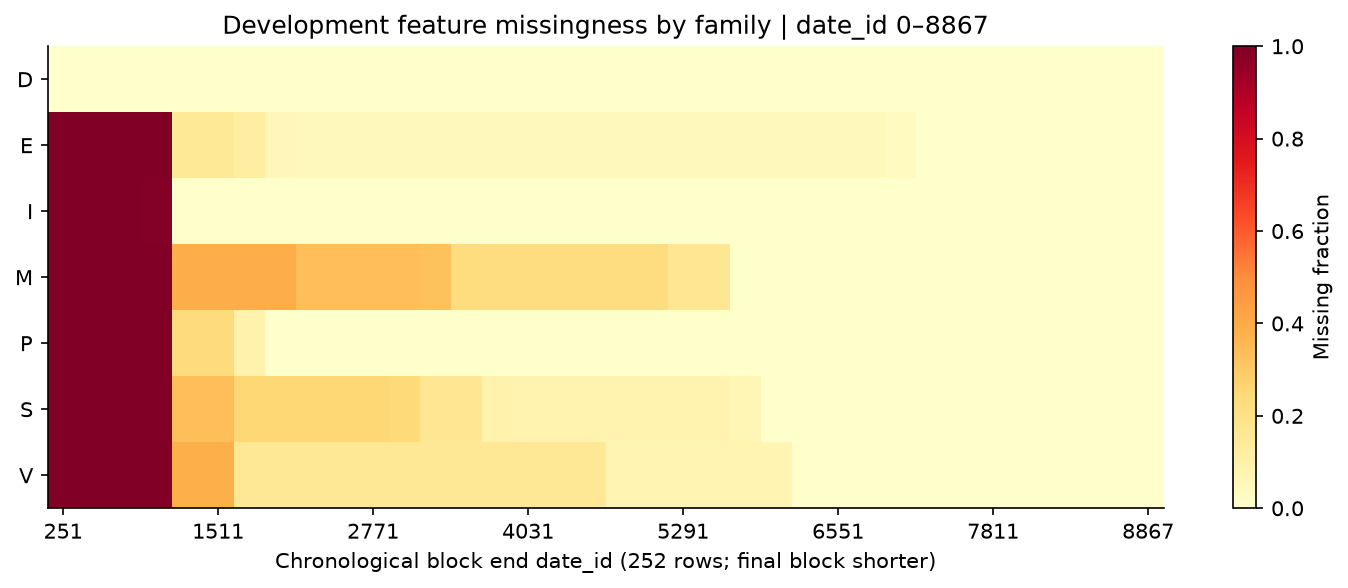

In [3]:
def table(name):
    return pd.read_csv(root / 'artifacts' / f'{name}.csv')

missing = table('missingness_summary')
assert len(missing) == 94
display(result['feature_missingness'])
display(missing.sort_values('missing_fraction', ascending=False).head(15))
display(table('missing_intervals').head(12))
display(table('family_time_blocks').groupby('family')['missing_fraction'].agg(['min','median','max']))
display(Image(filename=str(root / 'reports/figures/phase2_eda_missingness.png')))

## 3. Feature distributions and families

All 94 features have moments, quantiles, min/max, skewness and excess kurtosis. The complete table is saved, and observed D encodings are described separately. Family labels do not identify any numbered feature's exact economic meaning. No feature is removed for an unusual distribution.

In [4]:
statistics = table('feature_statistics')
assert len(statistics) == 94
display(statistics.head(12))
display(table('family_statistics'))
display(table('discrete_value_counts'))

,feature,family,dtype,observed,missing_count,unique_nonmissing,mean,std,median,min,max,skewness,excess_kurtosis,q01,q05,q25,q75,q95,q99
0,D1,D,int64,8868,0,2,0.031687,0.175175,0.000000,0.000000,1.000000,5.348001,26.607119,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
1,D2,D,int64,8868,0,2,0.031687,0.175175,0.000000,0.000000,1.000000,5.348001,26.607119,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
2,D3,D,int64,8868,0,2,0.047812,0.213381,0.000000,0.000000,1.000000,4.239267,15.974990,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
3,D4,D,int64,8868,0,2,0.578597,0.493812,1.000000,0.000000,1.000000,-0.318400,-1.899049,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000
4,D5,D,int64,8868,0,2,0.190573,0.392775,0.000000,0.000000,1.000000,1.575950,0.483728,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
5,D6,D,int64,8868,0,2,-0.237934,0.425843,0.000000,-1.000000,0.000000,-1.231088,-0.484530,-1.000000,-1.000000,0.000000,0.000000,0.000000,0.000000
6,D7,D,int64,8868,0,2,0.045670,0.208780,0.000000,0.000000,1.000000,4.353224,16.954386,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
7,D8,D,int64,8868,0,2,0.142760,0.349848,0.000000,0.000000,1.000000,2.042715,2.173176,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
8,D9,D,int64,8868,0,2,0.143099,0.350193,0.000000,0.000000,1.000000,2.038770,2.157068,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
9,E1,E,float64,7084,1784,7082,1.561876,0.638851,1.506334,0.325149,4.843911,1.102416,2.682676,0.406588,0.614795,1.110139,1.883217,2.595645,3.808530


,family,features,missing_count,missing_fraction,median_feature_mean,median_feature_std,smallest_feature_std,largest_feature_std,median_abs_feature_skewness,median_feature_excess_kurtosis
0,M,18,41254,0.258445,0.166018,1.058929,0.195697,1.564111,0.500139,-0.312346
1,E,20,27471,0.154888,0.122536,0.492867,0.012182,1.985658,1.108695,1.880656
2,I,9,9054,0.113442,0.551702,0.328160,0.243277,1.653419,0.407246,-0.330178
3,P,13,14888,0.129142,0.495701,0.818191,0.284115,1.453005,0.897055,0.231322
4,V,13,23170,0.200982,0.282517,0.347942,0.306559,1.334205,0.791966,-0.497949
5,S,12,21838,0.205214,0.341339,0.639433,0.288947,1.432591,0.181344,-0.862622
6,D,9,0,0.000000,0.047812,0.349848,0.175175,0.493812,2.042715,2.173176


,feature,family,kind,value,count
0,D1,D,binary,0,8587
1,D1,D,binary,1,281
2,D2,D,binary,0,8587
3,D2,D,binary,1,281
4,D3,D,binary,0,8444
5,D3,D,binary,1,424
6,D4,D,binary,0,3737
7,D4,D,binary,1,5131
8,D5,D,binary,0,7178
9,D5,D,binary,1,1690


## 4. X–X structure only

Pairwise-complete Pearson correlations require 126 observations. Pair counts are saved; high-correlation pairs are listed without feature selection. No target column is accepted by feature-analysis functions. Family absolute correlations exclude self-pairs. Pairwise deletion need not yield a positive-semidefinite matrix.

,feature_a,feature_b,family_a,family_b,pearson_xx,pairwise_observations
0,D1,D2,D,D,1.000000,8868
1,E11,E12,E,E,0.974262,7862
2,E2,E3,E,E,0.962249,7862
3,I5,I9,I,I,0.999688,7862
4,V10,V9,V,V,0.985354,2819
5,V2,V4,V,V,0.953411,7862
6,V7,V9,V,V,0.978425,4329


,family_a,family_b,defined_pairs,median_abs_pearson_xx,max_abs_pearson_xx
0,M,M,153,0.140185,0.715018
1,M,E,360,0.123553,0.749960
2,M,I,162,0.132352,0.742754
3,M,P,234,0.082407,0.906483
4,M,V,234,0.130458,0.939174
5,M,S,216,0.081401,0.698235
6,M,D,162,0.002913,0.161021
7,E,E,190,0.139405,0.974262
8,E,I,180,0.107573,0.545661
9,E,P,260,0.095346,0.895101


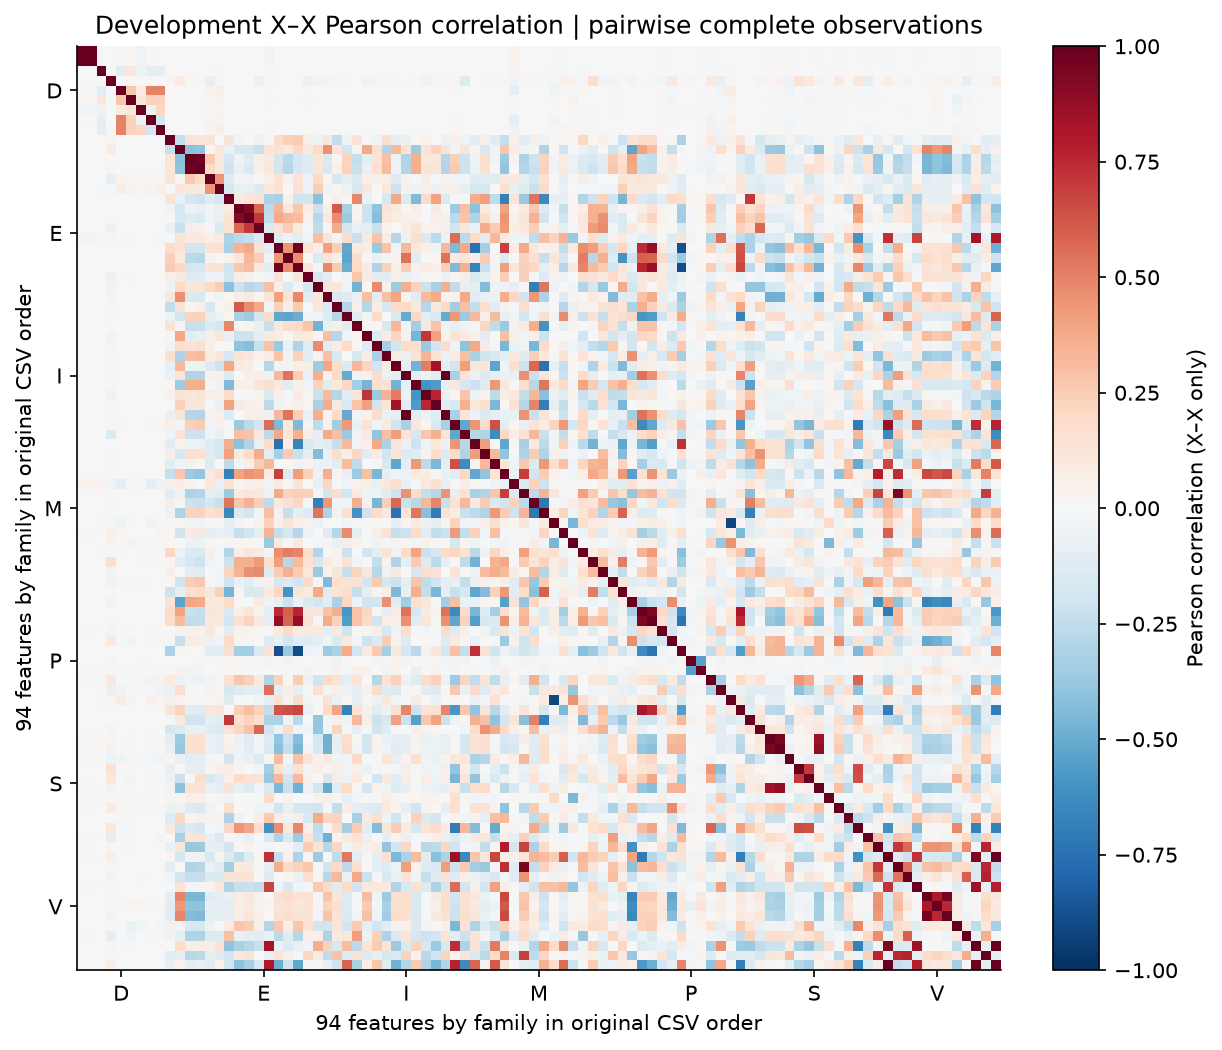

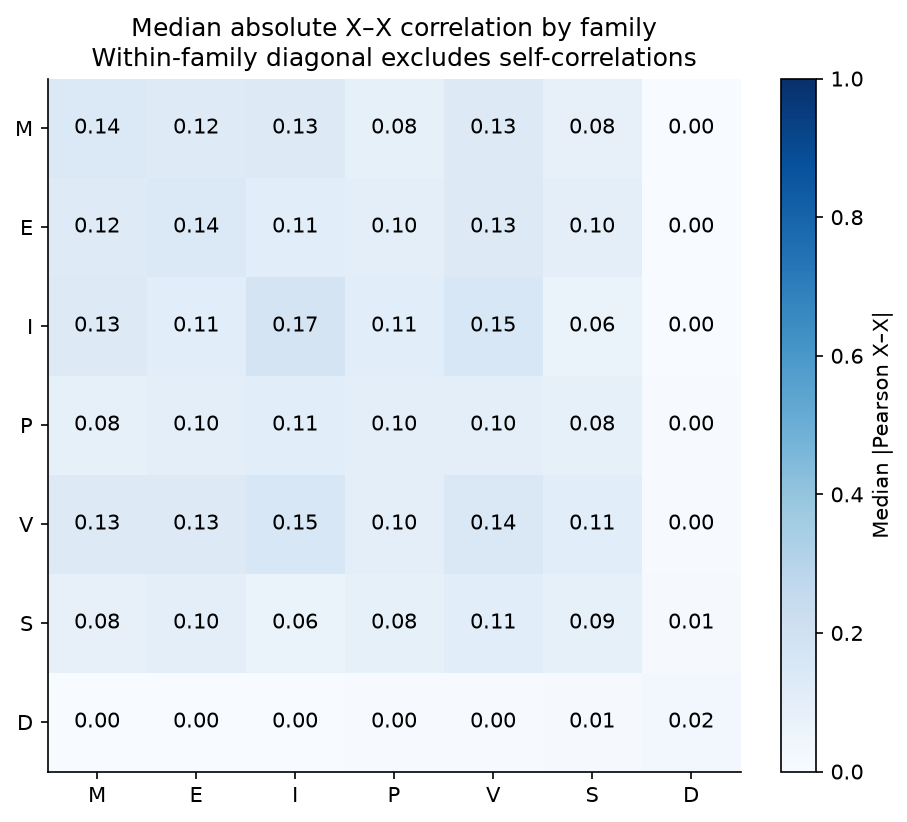

In [5]:
correlation = table('xx_correlation').set_index('feature')
assert correlation.shape == (94, 94)
assert 'market_forward_excess_returns' not in correlation.columns
display(table('high_xx_pairs'))
display(table('family_xx_correlation'))
display(Image(filename=str(root / 'reports/figures/phase2_eda_xx_correlation.png')))
display(Image(filename=str(root / 'reports/figures/phase2_eda_family_xx.png')))

## 5. Temporal distribution behavior

Trailing 252-row means/std require 126 observed values and end at the displayed row. Drift compares adjacent chronological 252-row blocks using an empirical CDF distance, mean change in prior standard deviations and std ratio, requiring 20 observations in each block. The last block has 48 rows. These are descriptive changes, not formal structural breaks, target-based regimes or predictive findings. Representative first-numbered features are selected for display without Y.

,ecdf_distance,std_ratio_to_prior
family,,
D,0.000000,1.000000
E,0.496032,0.983807
I,0.595238,0.883158
M,0.420635,1.000000
P,0.349206,0.997407
S,0.250000,1.000000
V,0.353175,1.000000


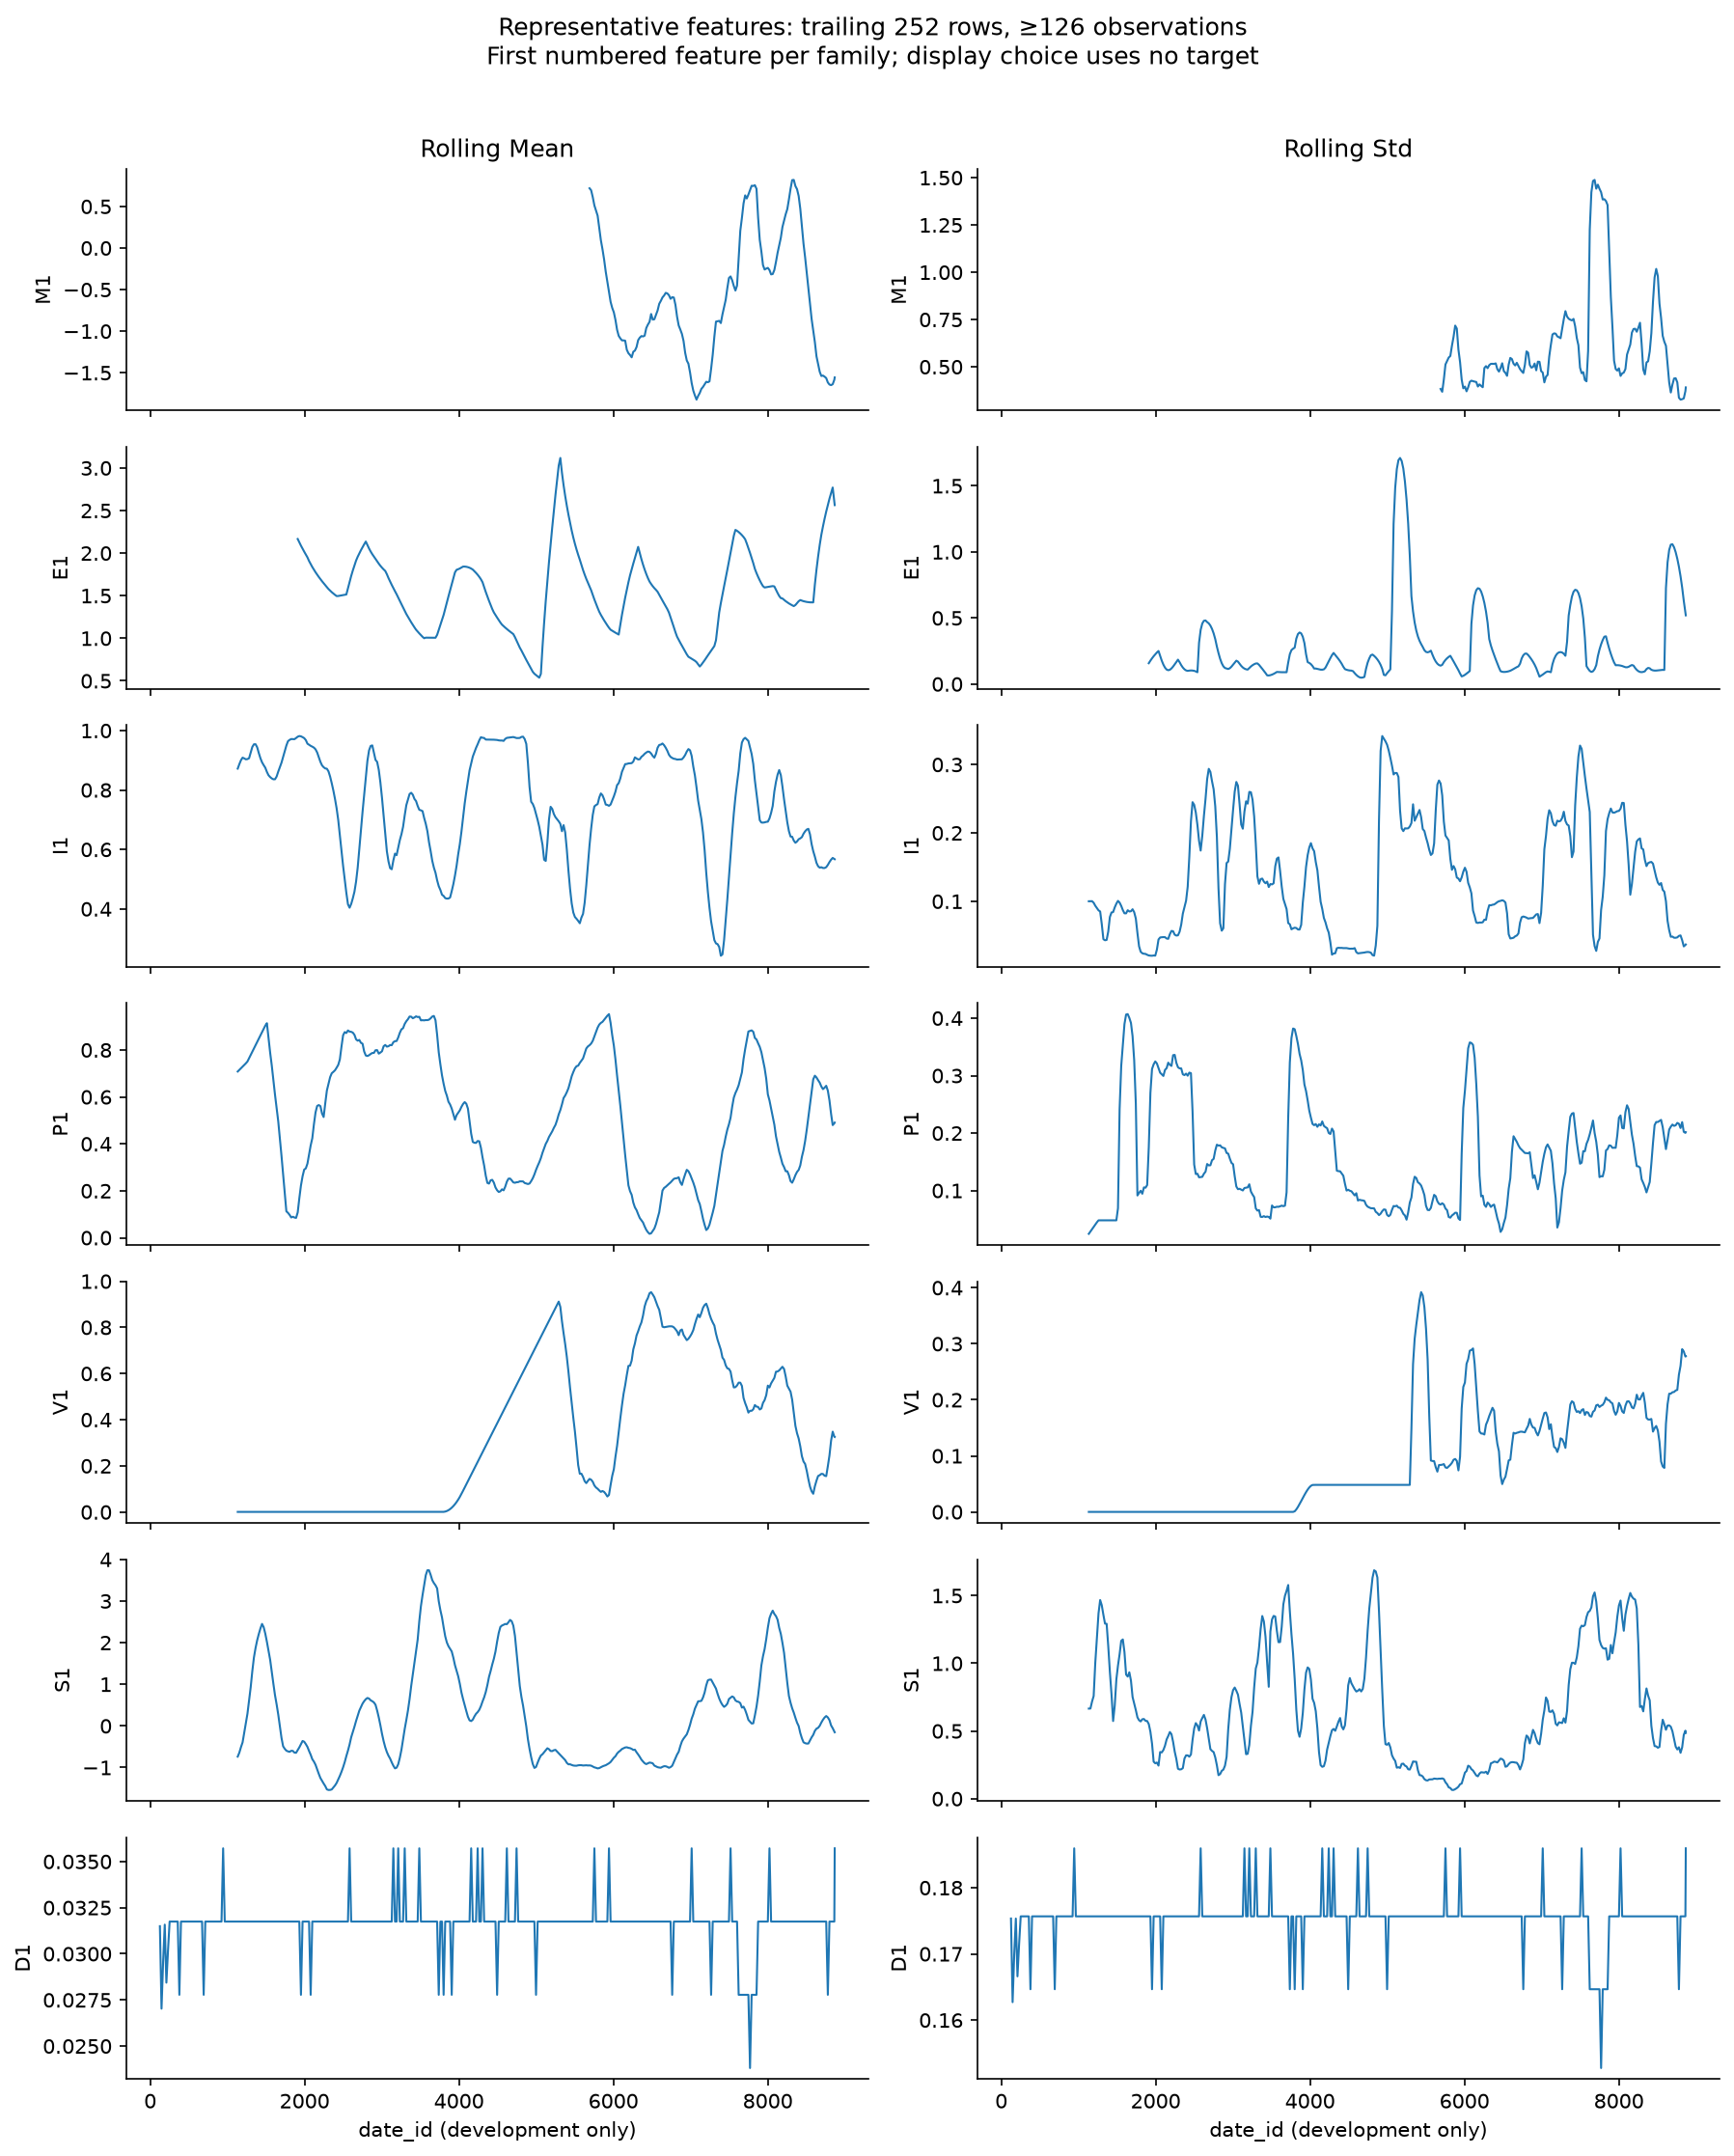

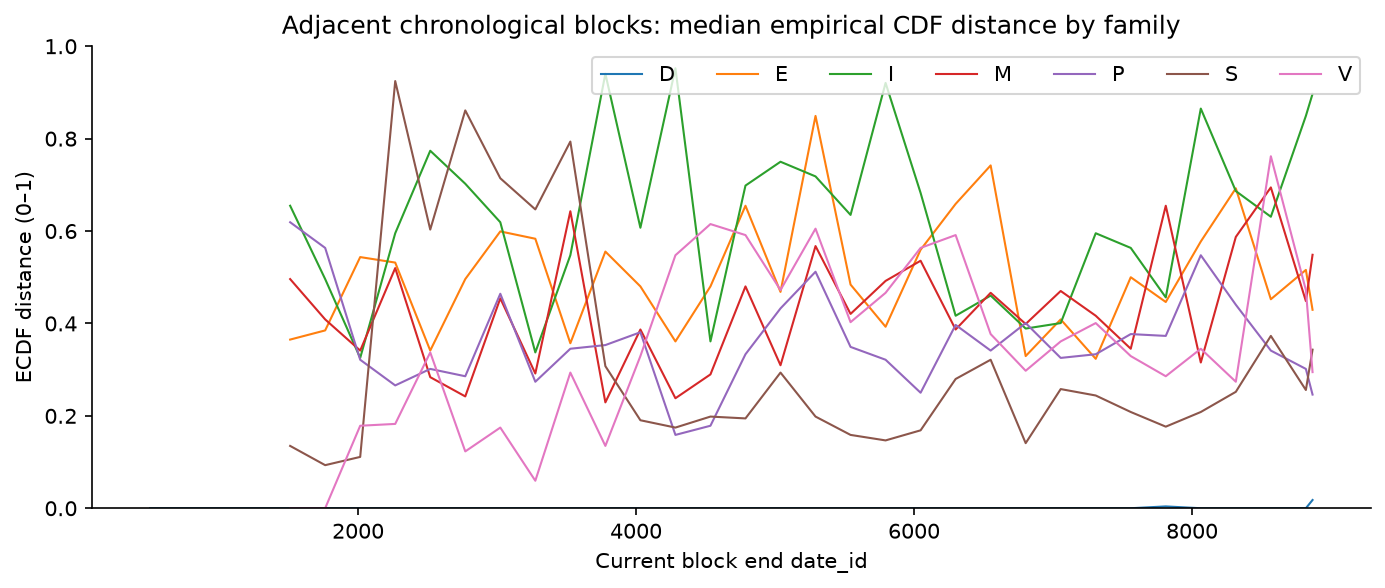

In [6]:
rolling = table('feature_rolling_statistics')
drift = table('distribution_drift')
assert rolling.date_id.max() == drift.end_date_id.max() == 8867
display(drift.groupby('family')[['ecdf_distance','std_ratio_to_prior']].median())
display(Image(filename=str(root / 'reports/figures/phase2_eda_feature_time.png')))
display(Image(filename=str(root / 'reports/figures/phase2_eda_distribution_drift.png')))

## 6. Target-only retrospective EDA

This analysis receives only market_forward_excess_returns and IDs from development. It describes the supplied distribution, quantiles, tails, trailing mean/std and lag-1..20 autocorrelation. It never joins X, ranks features or creates a regime. Rolling statistics include the current realized label and are not forecast-time predictors. Extreme observation details remain local ignored artifacts.

{'target': 'market_forward_excess_returns',
 'analysis_start': 0,
 'analysis_end': 8867,
 'rows': 8868,
 'observed': 8868,
 'missing_count': 0,
 'unique_nonmissing': 8866,
 'mean': 4.251953118019845e-05,
 'std': 0.01055680844594293,
 'median': 0.00024782905,
 'min': -0.04047555,
 'max': 0.04055108,
 'skewness': -0.17020905893681396,
 'excess_kurtosis': 2.2026474963651452,
 'q01': -0.0317831263,
 'q05': -0.018087395,
 'q25': -0.0047925005000000005,
 'q75': 0.0054741875,
 'q95': 0.016424056499999985,
 'q99': 0.03106380909999999}

,lag_rows,autocorrelation,paired_observations
0,1,-0.043677,8867
1,2,-0.019598,8866
2,3,-0.014462,8865
3,4,-0.014243,8864
4,5,-0.024002,8863
5,6,-0.026455,8862
6,7,0.003870,8861
7,8,-0.022846,8860
8,9,0.020113,8859
9,10,0.007682,8858


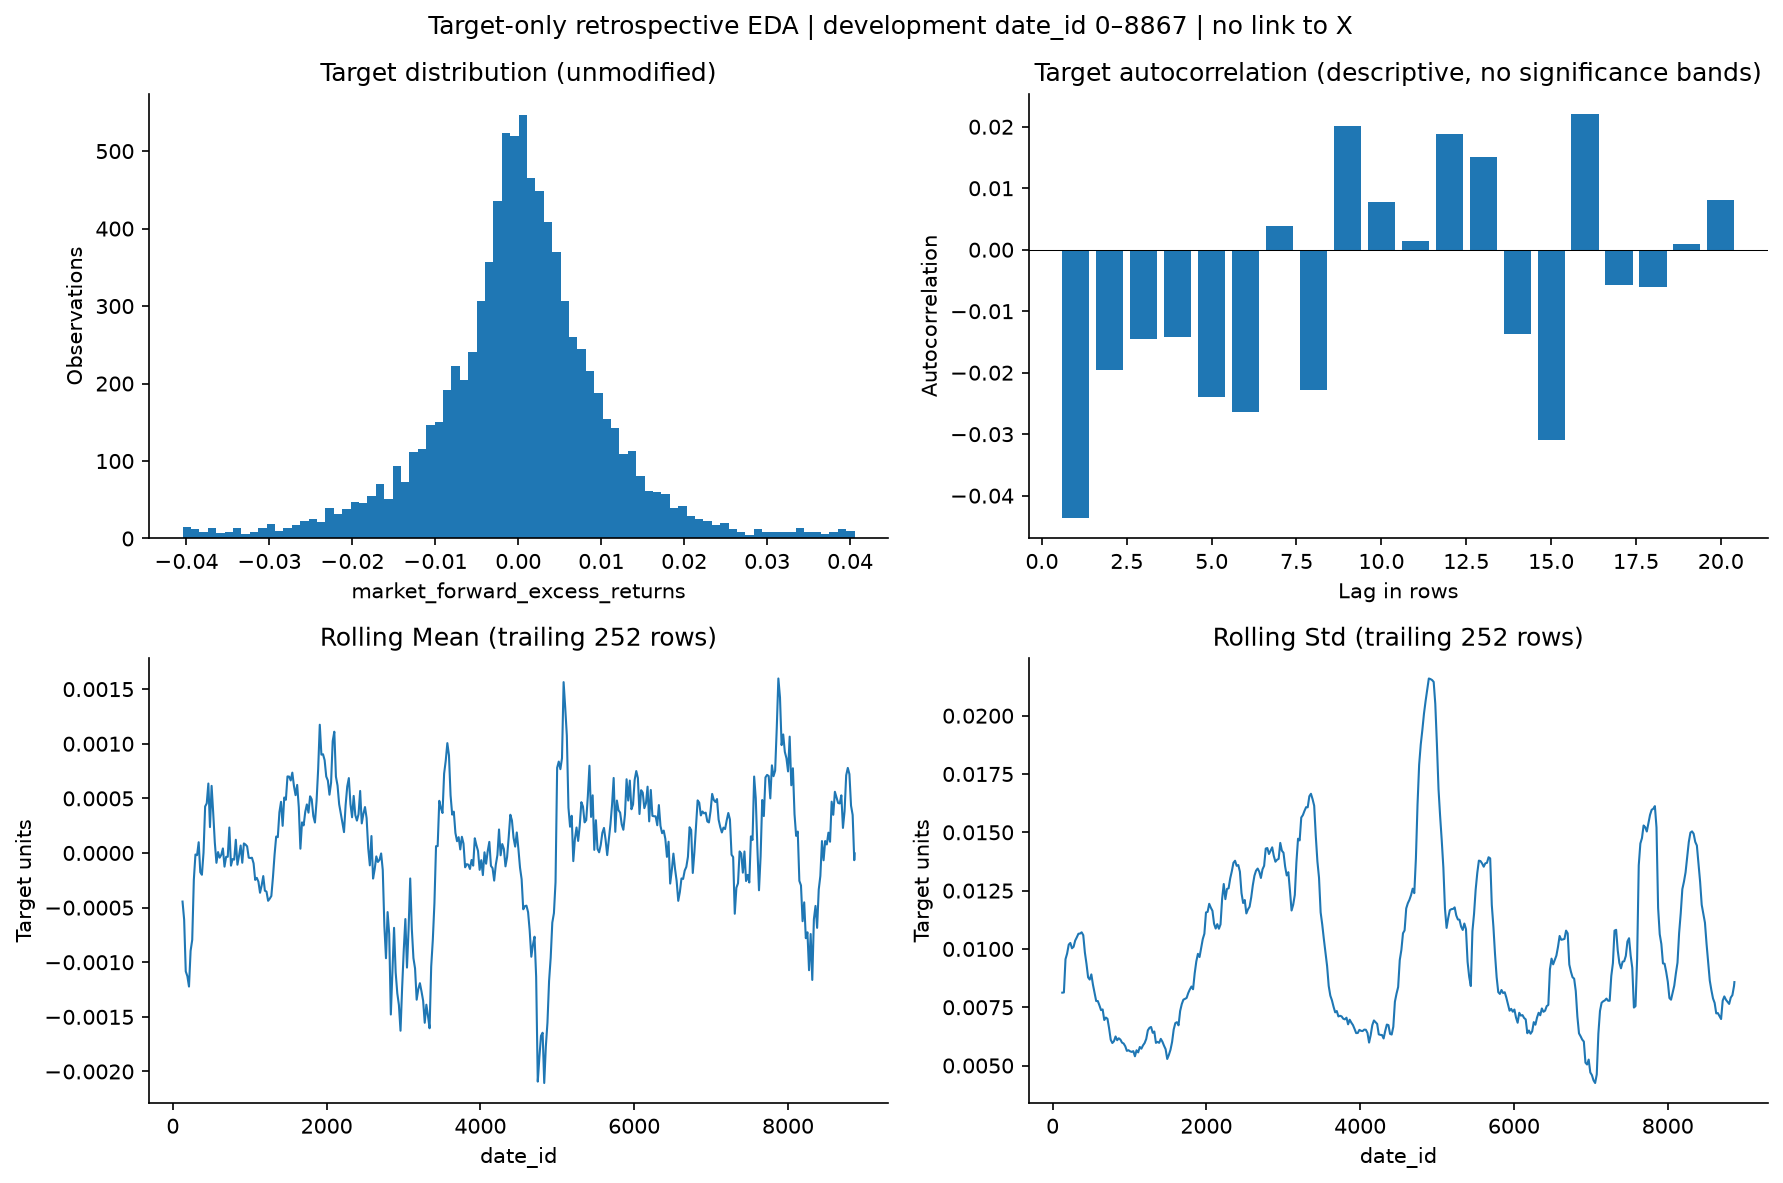

In [7]:
display(result['target_only'])
display(table('target_autocorrelation'))
display(Image(filename=str(root / 'reports/figures/phase2_eda_target_only.png')))

## 7. Default processing and future design

The processed development export is an identity copy: retain NaNs, all features, outcomes, encodings and outliers. Optional expanding strictly prior median and X missing-indicator helpers are tested but not applied. No global historical median/mean or backward fill is permitted.

Future development uses expanding-window walk-forward within 0–8867. Fold count, window lengths, internal holdout size, models, tuning and outcome-timing gaps are undecided. Define an internal holdout and strategy freeze before any separately authorized 180-row competition simulation. No folds are executed here.

The original Phase 1 audit predates the firewall and is preserved byte-for-byte. Previous inspection cannot be undone; the new lock is a prospective-use rule. No independent prediction result is claimed.

In [8]:
assert result['processing']['default'] == 'retain_nan'
assert result['processing']['values_changed'] is False
assert result['processing']['features_preserved'] == 94
assert result['processing']['outcomes_preserved'] == 3
assert result['split']['future_validation']['fold_count'] is None
assert result['split']['future_validation']['internal_holdout_rows'] is None
assert result['split']['future_validation']['selected_model'] is None
display(result['processing'])
display(result['execution'])
print('Saved:', root / 'reports/phase2_data_processing_eda.md')
print('Saved:', root / 'artifacts/phase2_data_summary.json')
print('No alpha discovery, predictive feature selection, model fitting, allocation optimization, or backtesting has been performed in the rebuilt Phase 2.')

{'default': 'retain_nan',
 'features_preserved': 94,
 'outcomes_preserved': 3,
 'values_changed': False,
 'rows_dropped': 0,
 'columns_dropped': 0,
 'optional_candidates_applied': False,
 'processed_path': 'data/processed/development.csv',
 'processed_sha256': 'edb6265a76dfdf014a604614584c72b9622aa2b86c2998ecea89e3720e6fe257'}

{'alpha_research': False,
 'models_fitted': 0,
 'folds_executed': 0,
 'oos_predictions': 0,
 'regime_research': False,
 'signals': False,
 'allocation': False,
 'backtest': False}

Saved: C:\Users\25473\Documents\Codex\2026-10-16\hull-alpha-forecasting-allocation\reports\phase2_data_processing_eda.md
Saved: C:\Users\25473\Documents\Codex\2026-10-16\hull-alpha-forecasting-allocation\artifacts\phase2_data_summary.json
No alpha discovery, predictive feature selection, model fitting, allocation optimization, or backtesting has been performed in the rebuilt Phase 2.
